# 淘宝用户行为分析：转化诊断、购买倾向预测与运营决策

业务问题：识别真实的行为路径与转化瓶颈；评估历史行为和未来购买的关联；在有限触达预算下优先筛选可能购买的活跃用户。

数据：2017-11-25 至 2017-12-03（北京时间），四类事件 `pv / cart / fav / buy`。本 Notebook 默认展示完整实验已生成的结果。需要重新计算时，将 `RECOMPUTE` 改为 `True` 后从第一格开始运行。核心实现位于 `src/`。

## 0. 环境与路径

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from run_analysis import main, ROOT, OUT

RECOMPUTE = False

def read_csv(name):
    return pd.read_csv(OUT / name)

def read_json(name):
    return json.loads((OUT / name).read_text(encoding='utf-8'))

def show_plot(name):
    display(Image(filename=str(OUT / name)))

print('Project:', ROOT)
print('Recompute:', RECOMPUTE)

Project: D:\projects\taobao User Behavior analysis
Recompute: False


## 1. 数据口径与质量审计

In [2]:
if RECOMPUTE:
    main('data')

audit = read_json('source_audit.json')
display(pd.Series(audit, name='value').to_frame())
reconciliation = read_csv('source_reconciliation.csv')
display(reconciliation.head(8))
assert reconciliation['difference'].eq(0).all()

,value
raw_events,100150807
outside_window_events,55576
invalid_events_inside_window,0
clean_events,100095231
clean_invalid_events,0
mismatched_day_behavior_groups,0
raw_bytes,3672347465
timezone,Asia/Shanghai (UTC+8)
period,"[2017-11-25, 2017-12-03]"


,action_date,behavior_type,expected_clean,n_clean,difference
0,2017-11-25,buy,201145,201145,0
1,2017-11-25,cart,563376,563376,0
2,2017-11-25,fav,302071,302071,0
3,2017-11-25,pv,9353423,9353423,0
4,2017-11-26,buy,205644,205644,0
5,2017-11-26,cart,582581,582581,0
6,2017-11-26,fav,308954,308954,0
7,2017-11-26,pv,9567423,9567423,0


## 2. 全量业务指标与时间分布

,value
event_count,100095231
active_users,987991
buyer_users,672404
pv_events,89660688
cart_events,5530446
fav_events,2888258
buy_events,2015839
observation_start,2017-11-25
observation_end,2017-12-03
buy_to_pv_event_ratio,0.022483


,date,event_count,active_users,buyer_users,buyer_share_pct
0,2017-11-25,10420015,706641,132622,18.77
1,2017-11-26,10664602,715516,136048,19.01
2,2017-11-27,10101147,710094,146934,20.69
3,2017-11-28,9878190,709257,139845,19.72
4,2017-11-29,10284073,718922,146220,20.34
5,2017-11-30,10447740,730597,146128,20.00
6,2017-12-01,10859436,740139,139971,18.91
7,2017-12-02,13777869,970401,174487,17.98
8,2017-12-03,13662159,966977,173225,17.91


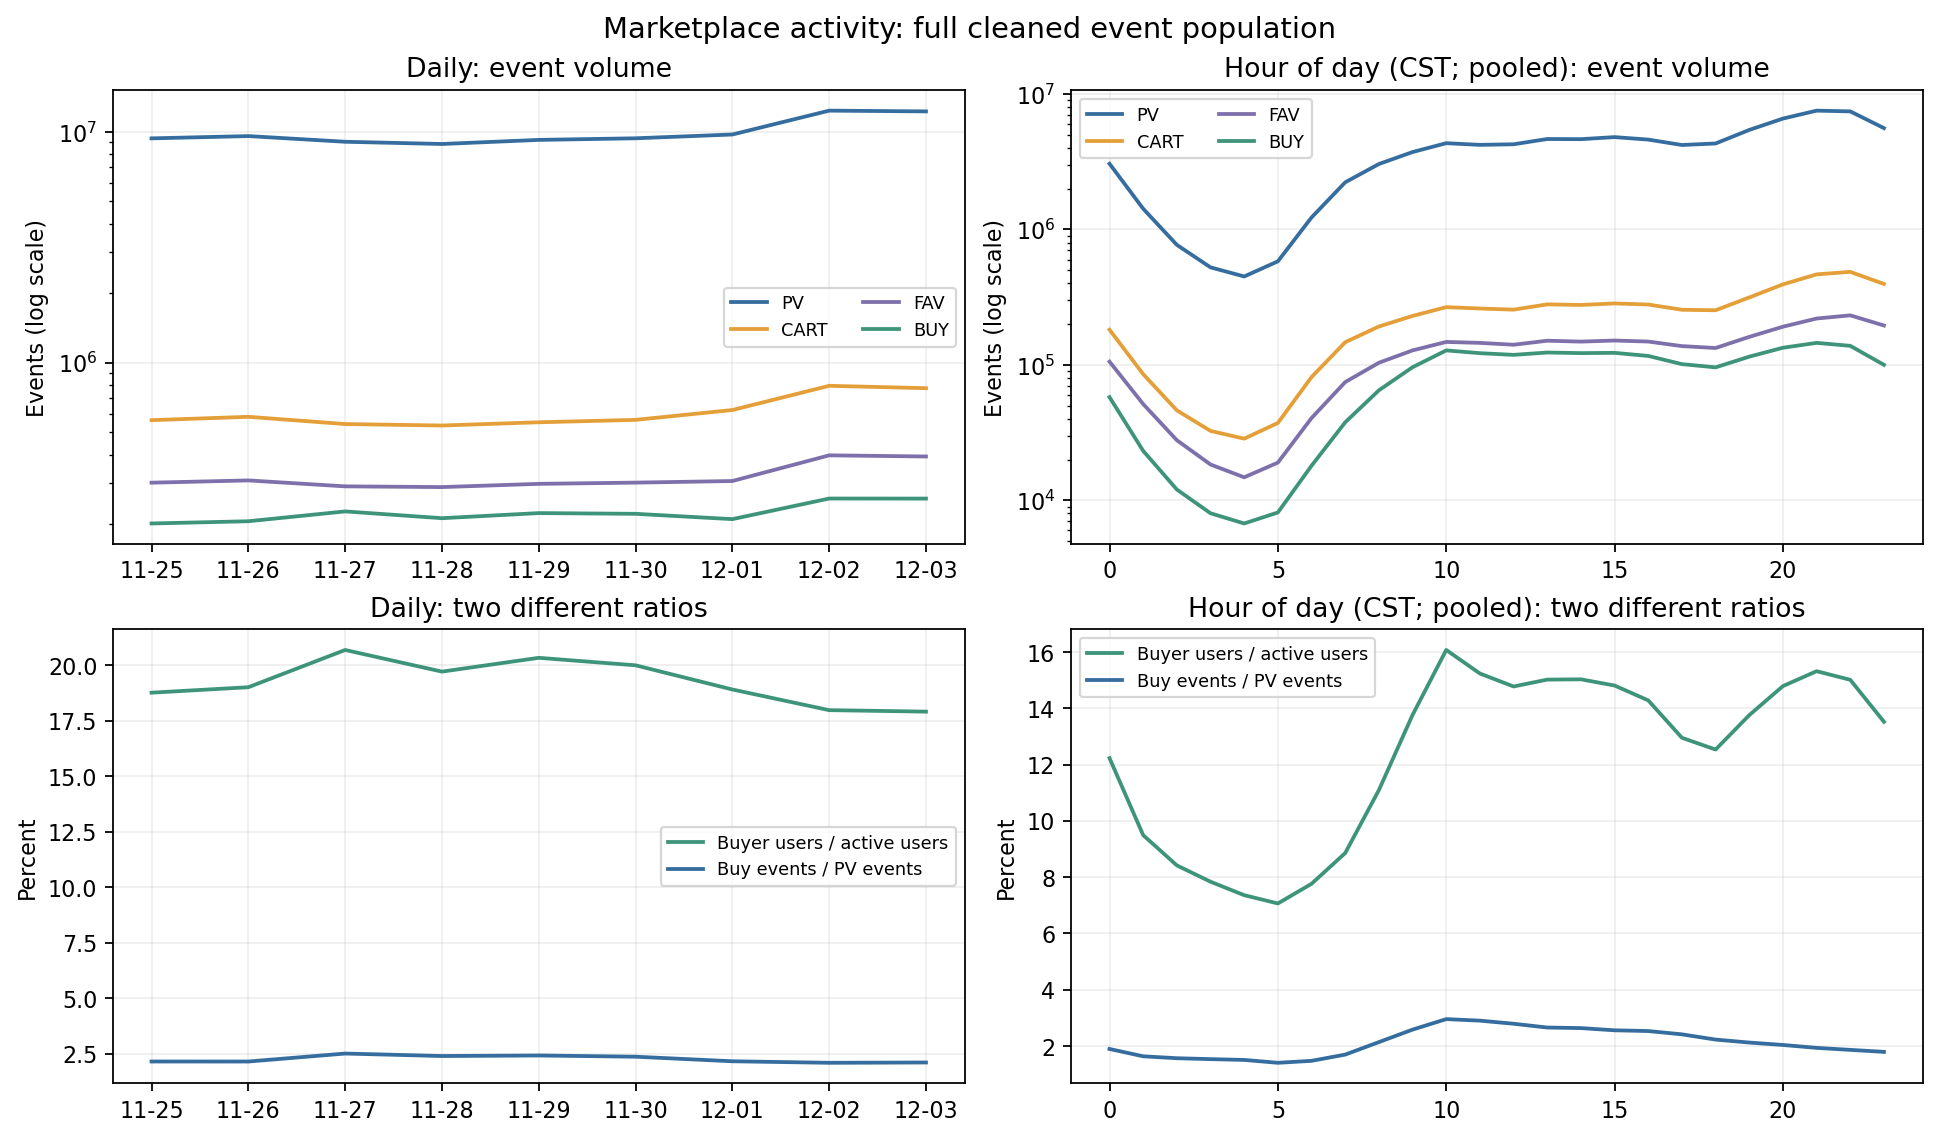

In [3]:
if RECOMPUTE:
    main('funnel')

summary = read_json('funnel_summary.json')
overall = summary['overall']
display(pd.Series(overall, name='value').to_frame())
daily = read_csv('daily_activity.csv')
daily['buyer_share_pct'] = 100 * daily.buyer_user_share
display(daily[['date', 'event_count', 'active_users', 'buyer_users', 'buyer_share_pct']].round(2))
show_plot('activity_profile.png')

## 3. 同用户、同商品的严格 24 小时漏斗

,stage,user_item_pairs,eligible_share_pct
0,eligible_first_pv,6145392,100.0000
1,pv_then_intent,70785,1.1518
2,pv_then_intent_then_purchase,4990,0.0812
3,pv_then_any_purchase,73129,1.1900
4,pv_then_purchase_no_confirmed_intent,68139,1.1088
5,pv_then_cart,50383,0.8199
6,pv_then_fav,21223,0.3453
7,pv_then_cart_then_purchase,3413,0.0555
8,pv_then_fav_then_purchase,1675,0.0273


Sampled users: 98,767
Intent → buy: 7.05%
No confirmed intermediate intent among purchases: 93.18%


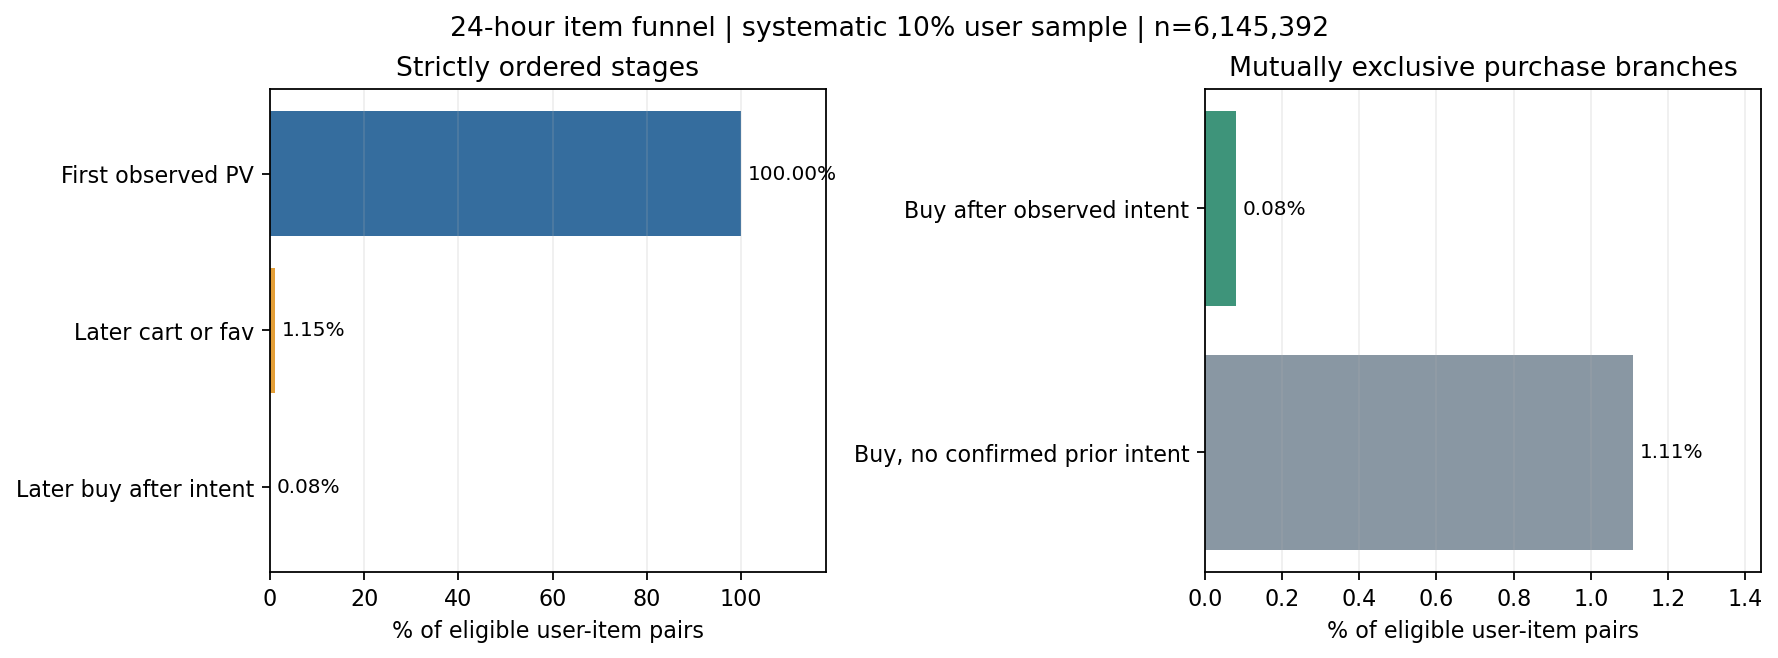

In [4]:
strict = summary['strict_funnel']
funnel = read_csv('strict_funnel.csv')
display(funnel[['stage', 'user_item_pairs', 'eligible_share_pct']].round(4))
print('Sampled users:', f"{strict['sample_users']:,}")
print('Intent → buy:', f"{strict['intent_to_purchase_pct']:.2f}%")
print('No confirmed intermediate intent among purchases:',
      f"{strict['no_confirmed_intent_share_of_purchases_pct']:.2f}%")
show_plot('strict_funnel.png')

## 4. 预测样本与时间切分

In [5]:
cohorts = read_csv('snapshot_cohorts.csv')
cohorts['buyer_share_pct'] = 100 * cohorts.buyer_share
display(cohorts.drop(columns='buyer_share').round(2))
print('Total labeled user-day snapshots:', f"{cohorts.eligible_users.sum():,}")
print('Feature window: previous 4 days; outcome: score date')

,score_date,fold,eligible_users,buyers,buyer_share_pct
0,2017-11-29,train,191950,28565,14.88
1,2017-11-30,train,192510,28491,14.80
2,2017-12-01,train,192308,27197,14.14
3,2017-12-02,validation,193259,34014,17.60
4,2017-12-03,test,197397,34580,17.52


Total labeled user-day snapshots: 967,424
Feature window: previous 4 days; outcome: score date


## 5. 可解释行为分层

In [6]:
segments = read_csv('behavior_segments.csv')
for name in ['buyer_share', 'share_of_users', 'share_of_buyers']:
    segments[name + '_pct'] = 100 * segments[name]
display(segments[['segment', 'users', 'buyers', 'buyer_share_pct',
                  'share_of_users_pct', 'share_of_buyers_pct']].round(2))

,segment,users,buyers,buyer_share_pct,share_of_users_pct,share_of_buyers_pct
0,Recent buyer,88259,19238,21.80,44.71,55.63
1,Cart / no recent buy,57602,9252,16.06,29.18,26.76
2,Favorite only / no recent buy,15829,1912,12.08,8.02,5.53
3,Browse only,35707,4178,11.70,18.09,12.08


## 6. 假设检验与分层标准化

,group,n,buyers,purchase_rate,ci_low,ci_high
0,no_cart,80314,11991,14.93%,14.69%,15.18%
1,cart,117083,22589,19.29%,19.07%,19.52%


,estimate,risk_difference_pp,ci_low_pp,ci_high_pp,p_value
0,crude,4.36,4.03,4.70,1.68e-138
1,standardized,3.48,3.13,3.83,nan


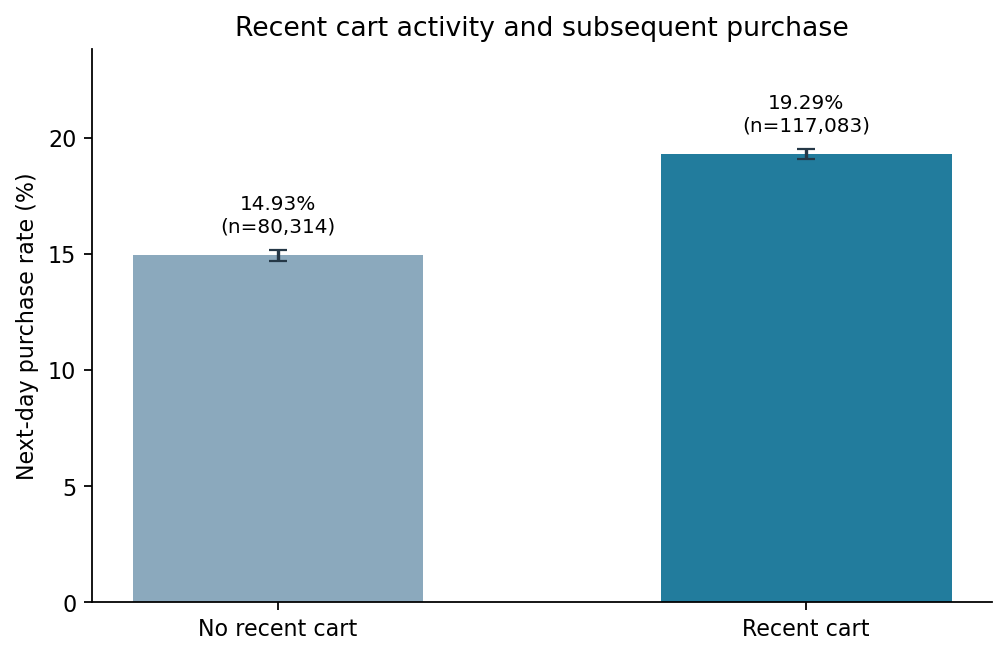

In [7]:
if RECOMPUTE:
    main('inference')

association = read_json('association_summary.json')
groups = read_csv('association_groups.csv')
display(groups.style.format({'purchase_rate': '{:.2%}', 'ci_low': '{:.2%}', 'ci_high': '{:.2%}'}))
effects = read_csv('association_effects.csv')
for name in ['risk_difference', 'ci_low', 'ci_high']:
    effects[name + '_pp'] = 100 * effects[name]
display(effects[['estimate', 'risk_difference_pp', 'ci_low_pp', 'ci_high_pp', 'p_value']].style.format(
    {'risk_difference_pp': '{:.2f}', 'ci_low_pp': '{:.2f}', 'ci_high_pp': '{:.2f}', 'p_value': '{:.2e}'}))
show_plot('association_cart.png')

## 7. 时间外预测与模型解释

Selected on validation AP: Histogram gradient boosting


,model,fold,ap,roc_auc,brier,base_rate,n
0,Logistic regression,validation,0.2366,0.5846,0.1437,0.1760,193259
1,Histogram gradient boosting,validation,0.2415,0.5860,0.1435,0.1760,193259
2,Logistic regression,test,0.2429,0.5994,0.1419,0.1752,197397
3,Histogram gradient boosting,test,0.2477,0.5994,0.1417,0.1752,197397


,feature,mean_ap_decrease,std_ap_decrease
0,buy_4d,0.0392,0.0005
1,buy_1d,0.0108,0.0003
2,pv_4d,0.0086,0.0003
3,active_days_4d,0.0033,0.0001
4,cart_4d,0.0017,0.0004
5,activity_4d,0.0013,0.0005
6,cart_1d,0.0005,0.0025
7,fav_1d,0.0002,0.0006


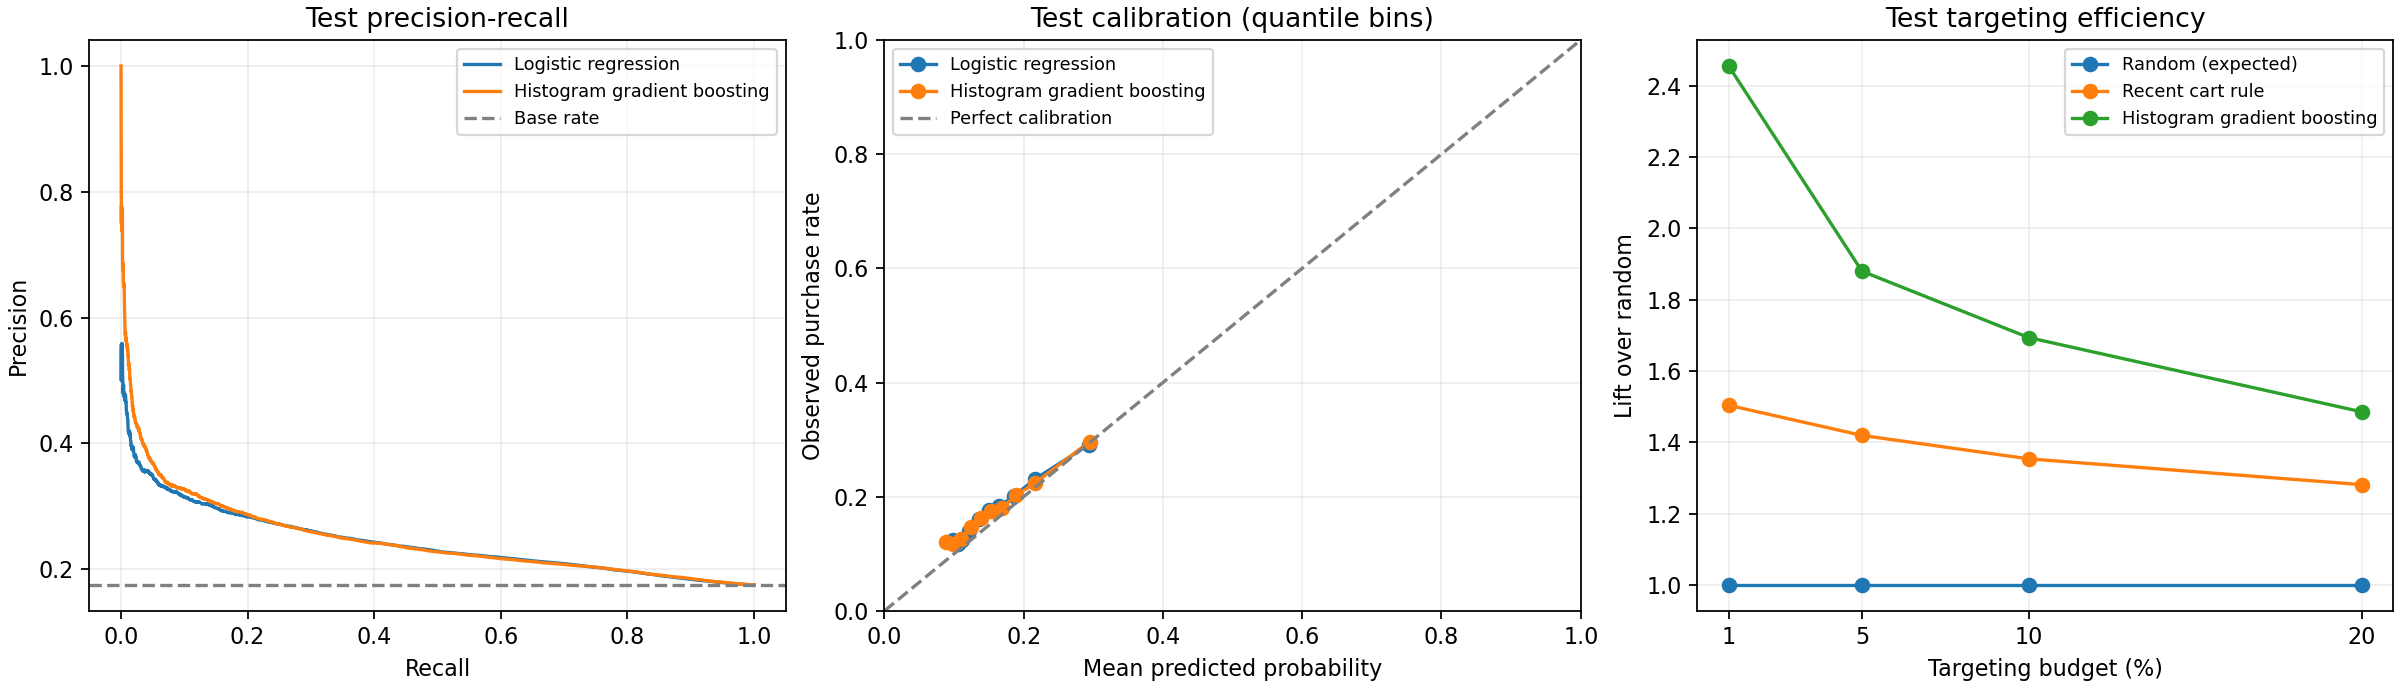

In [8]:
if RECOMPUTE:
    main('model')

model = read_json('model_summary.json')
metrics = read_csv('model_metrics.csv')
print('Selected on validation AP:', model['selected_model'])
display(metrics[['model', 'fold', 'ap', 'roc_auc', 'brier', 'base_rate', 'n']].round(4))
display(read_csv('model_importance.csv').head(8).round(4))
show_plot('model_diagnostics.png')

## 8. 相同触达预算下的离线运营决策

In [9]:
policy = read_csv('targeting_policy.csv')
top10 = policy.loc[policy.budget_fraction.eq(.10)].copy()
display(top10[['policy', 'n_selected', 'hits', 'precision', 'recall', 'lift']].round(4))
selected = top10.loc[top10.selected_model].iloc[0]
rule = top10.loc[top10.policy.eq('Recent cart rule')].iloc[0]
print(f"Selected-model precision gain vs cart rule: {100*(selected.precision-rule.precision):.2f} pp")
print(f"Additional naturally observed purchasers captured: {int(selected.hits-rule.hits):,}")
display(policy.pivot(index='budget_fraction', columns='policy', values='lift').round(3))

,policy,n_selected,hits,precision,recall,lift
2,Random (expected),19740,3458.0526,0.1752,0.1000,1.0000
6,Recent cart rule,19740,4681.0000,0.2371,0.1354,1.3537
10,Logistic regression,19740,5752.0000,0.2914,0.1663,1.6634
14,Histogram gradient boosting,19740,5857.0000,0.2967,0.1694,1.6937


Selected-model precision gain vs cart rule: 5.96 pp
Additional naturally observed purchasers captured: 1,176


policy,Histogram gradient boosting,Logistic regression,Random (expected),Recent cart rule
budget_fraction,,,,
0.01,2.455,2.175,1.0,1.504
0.05,1.880,1.826,1.0,1.419
0.10,1.694,1.663,1.0,1.354
0.20,1.485,1.492,1.0,1.281


## 9. 前瞻 A/B 实验设计

In [10]:
ab = read_csv('ab_sample_size_plan.csv')
display(ab.style.format({'historical_targeted_purchase_rate': '{:.2%}',
                         'hypothetical_mde_pp': '{:.1f}', 'alpha_two_sided': '{:.2f}', 'power': '{:.0%}'}))

,historical_targeted_purchase_rate,hypothetical_mde_pp,alpha_two_sided,power,users_per_arm,total_distinct_users
0,29.67%,0.5,0.05,80%,131661,263322
1,29.67%,1.0,0.05,80%,33071,66142
2,29.67%,2.0,0.05,80%,8344,16688


## 10. 结果闭环与边界

In [11]:
best = metrics.loc[(metrics.fold.eq('test')) & (metrics.model.eq(model['selected_model']))].iloc[0]
standardized = association['standardized']
display(Markdown(f"""- 清洗后 **{audit['clean_events']:,}** 条事件、**{overall['active_users']:,}** 名活跃用户；事件比值与有序路径采用不同口径。
- **{strict['eligible_pv_pairs']:,}** 个具有完整观测期的用户—商品对中，24 小时内购买占 **{strict['any_purchase_pct']:.2f}%**；有意向后购买占全部合格 PV 对的 **{strict['intent_purchase_pct']:.2f}%**。
- 历史加购与未来一天购买的分层标准化率差为 **{standardized['risk_difference']*100:.2f} pp**（95% 近似区间 {standardized['ci_low']*100:.2f}–{standardized['ci_high']*100:.2f} pp），仍是关联而非因果效应。
- 最终模型测试集 AP **{best.ap:.4f}**（基准率 {best.base_rate:.2%}），ROC-AUC {best.roc_auc:.4f}；在 Top 10% 预算下命中率 **{selected.precision:.2%}**，相对于随机为 **{selected.lift:.2f}×**，相对加购规则高 **{(selected.precision-rule.precision)*100:.2f} pp**。
- 建议：把模型排序作为触达候选筛选方案，并在随机对照实验中检验增量购买。"""))

- 清洗后 **100,095,231** 条事件、**987,991** 名活跃用户；事件比值与有序路径采用不同口径。
- **6,145,392** 个具有完整观测期的用户—商品对中，24 小时内购买占 **1.19%**；有意向后购买占全部合格 PV 对的 **0.08%**。
- 历史加购与未来一天购买的分层标准化率差为 **3.48 pp**（95% 近似区间 3.13–3.83 pp），仍是关联而非因果效应。
- 最终模型测试集 AP **0.2477**（基准率 17.52%），ROC-AUC 0.5994；在 Top 10% 预算下命中率 **29.67%**，相对于随机为 **1.69×**，相对加购规则高 **5.96 pp**。
- 建议：把模型排序作为触达候选筛选方案，并在随机对照实验中检验增量购买。